<a href="https://colab.research.google.com/github/LepingWan/ECE247A/blob/main/HW3.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Problem 1

**(a)** Minimizing the reconstruction error makes $W^TWx$ close to $x$. Since the reconstruction is computed from the compressed representation $Wx$, a small error means that $Wx$ retains enough information to approximately recover $x$.

**(b)** Define
$$
h=Wx,\qquad \hat{x}=W^Th,\qquad e=\hat{x}-x,\qquad L=\frac12e^Te.
$$
The computational graph is:

```text
W ------------+
              v
x ---------> [Wx] -> h -----> [W^T h] -> x_hat -> [x_hat - x] -> e -> [e^T e / 2] -> L
                                ^                    ^
W -----> [transpose] -----------+                    |
x --------------------------------------------------+
```

Both occurrences of $W$ refer to the same matrix.

**(c)** Temporarily separate the two occurrences:
$$
F(A,B)=\frac12\|B^TAx-x\|^2,\qquad L(W)=F(W,W).
$$
By the chain rule,
$$
\frac{\partial L}{\partial W_{ij}}
=\left.\frac{\partial F}{\partial A_{ij}}\right|_{A=B=W}
+\left.\frac{\partial F}{\partial B_{ij}}\right|_{A=B=W}.
$$
Thus, the gradient contributions from the encoder and decoder paths must be added.

**(d)** Starting from the loss,
$$
\frac{\partial L}{\partial \hat{x}}=e.
$$
For the decoder, $\hat{x}_i=\sum_j W_{ji}h_j$, so its contribution is
$$
\left(\frac{\partial L}{\partial W_{ji}}\right)_{\mathrm{decoder}}=e_i h_j,
\qquad (\nabla_WL)_{\mathrm{decoder}}=he^T.
$$
The gradient reaching $h$ is
$$
\frac{\partial L}{\partial h}=We.
$$
Since $h=Wx$, the encoder contribution is
$$
(\nabla_WL)_{\mathrm{encoder}}=(We)x^T.
$$
Adding the two,
$$
\boxed{\nabla_WL=(Wx)(W^TWx-x)^T+W(W^TWx-x)x^T.}
$$
Both terms have shape $m\times n$, matching $W$.


# Problem 2

Write
$$
K=\alpha XX^T+\beta^{-1}I.
$$
Since $K$ is symmetric, $K^{-T}=K^{-1}$.

**(a)** The computational graph for $L_1$ is:

```text
X ----------------------+
|                       v
+-> [transpose] -> X^T -> [multiply] -> XX^T -> [times alpha] -> [+ beta^(-1) I] -> K
                                                                                 |
                                                                                 v
L1 <- [times (-D/2)] <- [log] <- [determinant] <------------------------------------+
```

**(b)** First differentiate with respect to $K$:
$$
\frac{\partial L_1}{\partial K}=-\frac D2K^{-T}=-\frac D2K^{-1}.
$$
To backpropagate through $K=\alpha XX^T+\beta^{-1}I$, let
$$
G=\frac{\partial L_1}{\partial K}.
$$
Since
$$
K_{ij}=\alpha\sum_k X_{ik}X_{jk}+\beta^{-1}\delta_{ij},
$$
each $X_{ab}$ contributes through both factors:
$$
\frac{\partial L_1}{\partial X_{ab}}
=\alpha\sum_jG_{aj}X_{jb}+\alpha\sum_iG_{ia}X_{ib}.
$$
In matrix form,
$$
\frac{\partial L_1}{\partial X}=\alpha(G+G^T)X.
$$
Here $G$ is symmetric, giving
$$
\boxed{\frac{\partial L_1}{\partial X}=-\alpha D K^{-1}X.}
$$

**(c)** The computational graph for $L_2$ is:

```text
X ----------------------+
|                       v
+-> [transpose] -> X^T -> [multiply] -> XX^T -> [times alpha] -> [+ beta^(-1) I] -> K
                                                                                 |
                                                                                 v
                                                                             [inverse]
                                                                                 |
                                                                                 v
Y ----------------------+                                                       K^(-1)
|                       v                                                        |
+-> [transpose] -> Y^T -> [multiply] -> YY^T --------------------------------+     |
                                                                           v     v
                                                                           [multiply]
                                                                                |
                                                                                v
                                                                             [trace]
                                                                                |
                                                                                v
                                                                          [times (-1/2)]
                                                                                |
                                                                                v
                                                                                L2
```

**(d)** Let $Q=K^{-1}$. Then
$$
L_2=-\frac12\operatorname{tr}(QYY^T).
$$
Using $\partial\operatorname{tr}(QA)/\partial Q=A^T$,
$$
\frac{\partial L_2}{\partial Q}=-\frac12(YY^T)^T=-\frac12YY^T.
$$
Using the inverse derivative given in the problem,
$$
\frac{\partial L_2}{\partial K}
=-K^{-1}\frac{\partial L_2}{\partial K^{-1}}K^{-1}
=\frac12K^{-1}YY^TK^{-1}.
$$
This matrix is symmetric. Applying the same chain rule through $XX^T$ as in part (b),
$$
\begin{aligned}
\frac{\partial L_2}{\partial X}
&=\alpha\left(\frac{\partial L_2}{\partial K}+\left(\frac{\partial L_2}{\partial K}\right)^T\right)X\\
&=\boxed{\alpha K^{-1}YY^TK^{-1}X}.
\end{aligned}
$$

**(e)** The constant $-c$ has zero derivative, so
$$
\begin{aligned}
\frac{\partial L}{\partial X}
&=\frac{\partial L_1}{\partial X}+\frac{\partial L_2}{\partial X}\\
&=\boxed{\alpha\left(K^{-1}YY^TK^{-1}-DK^{-1}\right)X}.
\end{aligned}
$$


# Problem 3

**(a)** Define
$$
z=W_1x+b_1,\qquad h=\sigma(z),\qquad u=W_2h+b_2,\qquad \hat{y}=u+x.
$$

```text
        W1        b1                       W2        b2
         v         v                        v         v
x ---> [W1 x] --> [+] -> z -> [sigmoid] -> h -> [W2 h] -> [+] -> u --> [+] -> y_hat
|                                                                    ^        |
+-------------------------- identity --------------------------------+        v
                                                                         [y_hat - y] <-- y
                                                                              |
                                                                              v
                                                                              e
                                                                              |
                                                                              v
                                                                         [e^T e / 2]
                                                                              |
                                                                              v
                                                                              L
```

**(b)** Let
$$
e=\hat{y}-y=W_2h+b_2+x-y.
$$
Then
$$
\frac{\partial L}{\partial\hat{y}}=e.
$$
The addition $\hat{y}=u+x$ passes the same gradient to $u$:
$$
\frac{\partial L}{\partial u}=e.
$$
Since $u_i=\sum_j(W_2)_{ij}h_j+(b_2)_i$,
$$
\frac{\partial L}{\partial(W_2)_{ij}}=e_i h_j.
$$
Thus,
$$
\boxed{\nabla_{W_2}L=eh^T.}
$$

**(c)** Since $\partial u_i/\partial(b_2)_j=\delta_{ij}$,
$$
\boxed{\nabla_{b_2}L=e=\hat{y}-y.}
$$
The residual connection changes the value of $\hat{y}$, and hence $e$, but the local derivative with respect to $b_2$ is still the identity.

**(d)** Backpropagating through $u=W_2h+b_2$,
$$
\frac{\partial L}{\partial h}=W_2^Te.
$$
For the sigmoid,
$$
\sigma'(z_i)=\sigma(z_i)(1-\sigma(z_i))=h_i(1-h_i).
$$
Applying the chain rule element by element,
$$
\frac{\partial L}{\partial z_i}=(W_2^Te)_i h_i(1-h_i).
$$
Let
$$
\delta=(W_2^Te)\odot h\odot(1-h),
$$
where $\odot$ means element-wise multiplication.

Since $z_i=\sum_j(W_1)_{ij}x_j+(b_1)_i$,
$$
\frac{\partial L}{\partial(W_1)_{ij}}=\delta_i x_j.
$$
Therefore,
$$
\boxed{\nabla_{W_1}L=\left[(W_2^Te)\odot h\odot(1-h)\right]x^T.}
$$
The skip connection affects this gradient through
$$
e=W_2h+b_2+x-y.
$$
There is no separate skip-path term for $W_1$, because the added $x$ does not depend on $W_1$.

**(e)** Since $\partial z_i/\partial(b_1)_j=\delta_{ij}$,
$$
\boxed{\nabla_{b_1}L=(W_2^Te)\odot h\odot(1-h).}
$$


## Two-layer neural network - Homework #3

**Neural Networks & Deep Learning - ECE C147A/C247A, UCLA Fall 2026**  
**Instructor:** Prof. Suhas Diggavi  
**TAs:** A. Kadiyala, B. Huang, M.Y. Turali, K. Pang, S.Y. Yetim  
**Released:** Monday, October 12, 2026  
**Due:** Friday, October 23, 2026, 11:59 PM Pacific Time  
**HW3 Problem 4:** 30 points

Please follow the notebook linearly to implement a two layer neural network.

Please print out the workbook entirely when completed.

We thank Serena Yeung & Justin Johnson for permission to use code written for the CS 231n class (cs231n.stanford.edu).  These are the functions in the cs231n folders and code in the jupyer notebook to preprocess and show the images.  The classifiers used are based off of code prepared for CS 231n as well.

The goal of this workbook is to give you experience with training a two layer neural network.

In [1]:
import random
import numpy as np
import matplotlib.pyplot as plt

%matplotlib inline

def rel_error(x, y):
    return np.max(np.abs(x - y) / np.maximum(1e-8, np.abs(x) + np.abs(y)))


## Toy example

Before loading CIFAR-10, there will be a toy example to test your implementation of the forward and backward pass

In [2]:
class TwoLayerNet:
    def __init__(self, input_size, hidden_size, output_size, std=1e-4):
        self.params = {
            'W1': std * np.random.randn(hidden_size, input_size),
            'b1': np.zeros(hidden_size),
            'W2': std * np.random.randn(output_size, hidden_size),
            'b2': np.zeros(output_size),
        }

    def loss(self, X, y=None, reg=0.0):
        W1, b1 = self.params['W1'], self.params['b1']
        W2, b2 = self.params['W2'], self.params['b2']
        N = X.shape[0]

        hidden = np.maximum(0, X @ W1.T + b1)
        scores = hidden @ W2.T + b2
        if y is None:
            return scores

        # Subtract the largest score before exponentiating.
        shifted = scores - np.max(scores, axis=1, keepdims=True)
        log_probs = shifted - np.log(np.sum(np.exp(shifted), axis=1, keepdims=True))
        loss = -np.mean(log_probs[np.arange(N), y])
        loss += 0.5 * reg * (np.sum(W1 * W1) + np.sum(W2 * W2))

        dscores = np.exp(log_probs)
        dscores[np.arange(N), y] -= 1
        dscores /= N
        grads = {}
        grads['W2'] = dscores.T @ hidden + reg * W2
        grads['b2'] = np.sum(dscores, axis=0)
        dhidden = dscores @ W2
        dhidden[hidden <= 0] = 0
        grads['W1'] = dhidden.T @ X + reg * W1
        grads['b1'] = np.sum(dhidden, axis=0)
        return loss, grads

    def train(self, X, y, X_val, y_val, learning_rate=1e-3,
              learning_rate_decay=0.95, reg=1e-5, num_iters=100,
              batch_size=200, verbose=False):
        num_train = X.shape[0]
        iterations_per_epoch = max(num_train // batch_size, 1)
        loss_history, train_acc_history, val_acc_history = [], [], []
        best_val_acc = -1.0
        best_params = None
        best_iteration = 0

        for it in range(num_iters):
            indices = np.random.choice(num_train, batch_size, replace=True)
            X_batch, y_batch = X[indices], y[indices]
            loss, grads = self.loss(X_batch, y_batch, reg=reg)
            loss_history.append(float(loss))
            for name in self.params:
                self.params[name] -= learning_rate * grads[name]

            if verbose and (it % 500 == 0 or it == num_iters - 1):
                print('iteration %d / %d: loss %.4f' % (it, num_iters, loss))

            if (it + 1) % iterations_per_epoch == 0 or it == num_iters - 1:
                train_acc = np.mean(self.predict(X_batch) == y_batch)
                val_acc = np.mean(self.predict(X_val) == y_val)
                train_acc_history.append(float(train_acc))
                val_acc_history.append(float(val_acc))
                if val_acc > best_val_acc:
                    best_val_acc = float(val_acc)
                    best_iteration = it + 1
                    best_params = {name: value.copy() for name, value in self.params.items()}
                learning_rate *= learning_rate_decay

        return {
            'loss_history': loss_history,
            'train_acc_history': train_acc_history,
            'val_acc_history': val_acc_history,
            'best_val_acc': best_val_acc,
            'best_params': best_params,
            'best_iteration': best_iteration,
        }

    def predict(self, X):
        return np.argmax(self.loss(X), axis=1)


In [3]:
# Create a small net and some toy data to check your implementations.
# Note that we set the random seed for repeatable experiments.

input_size = 4
hidden_size = 10
num_classes = 3
num_inputs = 5

def init_toy_model():
    np.random.seed(0)
    return TwoLayerNet(input_size, hidden_size, num_classes, std=1e-1)

def init_toy_data():
    np.random.seed(1)
    X = 10 * np.random.randn(num_inputs, input_size)
    y = np.array([0, 1, 2, 2, 1])
    return X, y

net = init_toy_model()
X, y = init_toy_data()

### Compute forward pass scores

In [4]:
## Implement the forward pass of the neural network.

# Note, there is a statement if y is None: return scores, which is why
# the following call will calculate the scores.
scores = net.loss(X)
print('Your scores:')
print(scores)
print()
print('correct scores:')
correct_scores = np.asarray([
    [-1.07260209,  0.05083871, -0.87253915],
    [-2.02778743, -0.10832494, -1.52641362],
    [-0.74225908,  0.15259725, -0.39578548],
    [-0.38172726,  0.10835902, -0.17328274],
    [-0.64417314, -0.18886813, -0.41106892]])
print(correct_scores)
print()

# The difference should be very small. We get < 1e-7
print('Difference between your scores and correct scores:')
print(np.sum(np.abs(scores - correct_scores)))
assert np.sum(np.abs(scores - correct_scores)) < 1e-7


Your scores:
[[-1.07260209  0.05083871 -0.87253915]
 [-2.02778743 -0.10832494 -1.52641362]
 [-0.74225908  0.15259725 -0.39578548]
 [-0.38172726  0.10835902 -0.17328274]
 [-0.64417314 -0.18886813 -0.41106892]]

correct scores:
[[-1.07260209  0.05083871 -0.87253915]
 [-2.02778743 -0.10832494 -1.52641362]
 [-0.74225908  0.15259725 -0.39578548]
 [-0.38172726  0.10835902 -0.17328274]
 [-0.64417314 -0.18886813 -0.41106892]]

Difference between your scores and correct scores:
3.381231220012104e-08


### Forward pass loss

In [5]:
loss, _ = net.loss(X, y, reg=0.05)
correct_loss = 1.071696123862817

# should be very small, we get < 1e-12
print('Difference between your loss and correct loss:')
print(np.sum(np.abs(loss - correct_loss)))
assert abs(loss - correct_loss) < 1e-12


Difference between your loss and correct loss:
0.0


In [6]:
print(loss)

1.071696123862817


### Backward pass

Implements the backwards pass of the neural network.  Check your gradients with the gradient check utilities provided.

In [7]:
def eval_numerical_gradient(f, x, verbose=True, h=0.00001):
  """
  a naive implementation of numerical gradient of f at x
  - f should be a function that takes a single argument
  - x is the point (numpy array) to evaluate the gradient at
  """

  fx = f(x) # evaluate function value at original point
  grad = np.zeros_like(x)
  # iterate over all indexes in x
  it = np.nditer(x, flags=['multi_index'], op_flags=['readwrite'])
  while not it.finished:

    # evaluate function at x+h
    ix = it.multi_index
    oldval = x[ix]
    x[ix] = oldval + h # increment by h
    fxph = f(x) # evalute f(x + h)
    x[ix] = oldval - h
    fxmh = f(x) # evaluate f(x - h)
    x[ix] = oldval # restore

    # compute the partial derivative with centered formula
    grad[ix] = (fxph - fxmh) / (2 * h) # the slope
    if verbose:
      print(ix, grad[ix])
    it.iternext() # step to next dimension

  return grad

# Use numeric gradient checking to check your implementation of the backward pass.
# If your implementation is correct, the difference between the numeric and
# analytic gradients should be less than 1e-8 for each of W1, W2, b1, and b2.

loss, grads = net.loss(X, y, reg=0.05)

# these should all be less than 1e-8 or so
for param_name in grads:
    f = lambda W: net.loss(X, y, reg=0.05)[0]
    param_grad_num = eval_numerical_gradient(f, net.params[param_name], verbose=False)
    print('{} max relative error: {}'.format(param_name, rel_error(param_grad_num, grads[param_name])))
    assert rel_error(param_grad_num, grads[param_name]) < 1e-8

W2 max relative error: 2.963218723508599e-10
b2 max relative error: 1.616097450384273e-09
W1 max relative error: 1.283274044162582e-09
b1 max relative error: 3.1726810576715883e-09


### Training the network

Implement neural_net.train() to train the network via stochastic gradient descent, much like the softmax and SVM.

Final training loss:  0.014497864587765875


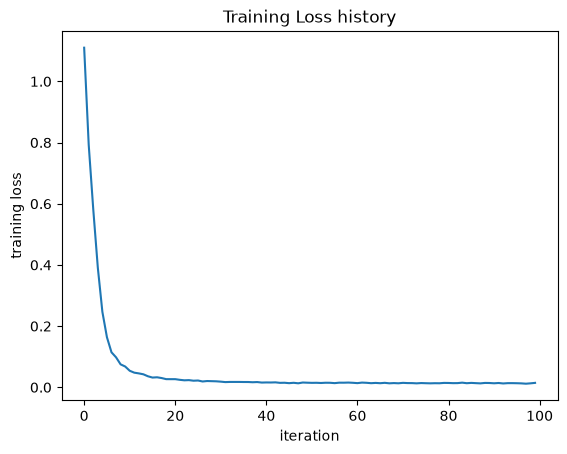

In [8]:
net = init_toy_model()
stats = net.train(X, y, X, y,
            learning_rate=1e-1, reg=5e-6,
            num_iters=100, verbose=False)

print('Final training loss: ', stats['loss_history'][-1])

# plot the loss history
plt.plot(stats['loss_history'])
plt.xlabel('iteration')
plt.ylabel('training loss')
plt.title('Training Loss history')
plt.show()

## Classify CIFAR-10

Do classification on the CIFAR-10 dataset.

Dataset: [CIFAR-10](https://www.cs.toronto.edu/~kriz/cifar.html), Alex Krizhevsky, *Learning Multiple Layers of Features from Tiny Images* (2009). The next cell downloads the Python archive if needed.


In [9]:
import hashlib
import pickle
import tarfile
from pathlib import Path
from urllib.request import urlretrieve


def load_CIFAR10(root):
    # Same image layout as the supplied cs231n loader, using float32 to save memory.
    def load_batch(filename):
        with open(Path(root) / filename, 'rb') as f:
            batch = pickle.load(f, encoding='latin1')
        images = batch['data'].reshape(-1, 3, 32, 32).transpose(0, 2, 3, 1)
        return images.astype(np.float32), np.array(batch['labels'])

    batches = [load_batch('data_batch_%d' % i) for i in range(1, 6)]
    X_train = np.concatenate([batch[0] for batch in batches])
    y_train = np.concatenate([batch[1] for batch in batches])
    X_test, y_test = load_batch('test_batch')
    return X_train, y_train, X_test, y_test


def prepare_CIFAR10():
    root = Path('cifar-10-batches-py')
    if not (root / 'test_batch').exists():
        archive = Path('cifar-10-python.tar.gz')
        if not archive.exists():
            print('Downloading CIFAR-10...')
            urlretrieve('https://www.cs.toronto.edu/~kriz/cifar-10-python.tar.gz', archive)
        with open(archive, 'rb') as f:
            checksum = hashlib.file_digest(f, 'md5').hexdigest()
        if checksum != 'c58f30108f718f92721af3b95e74349a':
            raise ValueError('CIFAR-10 download is incomplete; remove the archive and rerun.')
        with tarfile.open(archive, 'r:gz') as f:
            f.extractall(path='.', filter='data')
    return root


def get_CIFAR10_data(num_training=49000, num_validation=1000, num_test=1000):
    """
    Load the CIFAR-10 dataset from disk and perform preprocessing to prepare
    it for the two-layer neural net classifier. These are the same steps as
    we used for the SVM, but condensed to a single function.
    """
    # Load the raw CIFAR-10 data
    cifar10_dir = prepare_CIFAR10()
    X_train, y_train, X_test, y_test = load_CIFAR10(cifar10_dir)

    # Subsample the data
    mask = list(range(num_training, num_training + num_validation))
    X_val = X_train[mask]
    y_val = y_train[mask]
    mask = list(range(num_training))
    X_train = X_train[mask]
    y_train = y_train[mask]
    mask = list(range(num_test))
    X_test = X_test[mask]
    y_test = y_test[mask]

    # Normalize the data: subtract the mean image
    mean_image = np.mean(X_train, axis=0)
    X_train -= mean_image
    X_val -= mean_image
    X_test -= mean_image

    # Reshape data to rows
    X_train = X_train.reshape(num_training, -1)
    X_val = X_val.reshape(num_validation, -1)
    X_test = X_test.reshape(num_test, -1)

    return X_train, y_train, X_val, y_val, X_test, y_test


# Invoke the above function to get our data.
X_train, y_train, X_val, y_val, X_test, y_test = get_CIFAR10_data()
print('Train data shape: ', X_train.shape)
print('Train labels shape: ', y_train.shape)
print('Validation data shape: ', X_val.shape)
print('Validation labels shape: ', y_val.shape)
print('Test data shape: ', X_test.shape)
print('Test labels shape: ', y_test.shape)

Train data shape:  (49000, 3072)
Train labels shape:  (49000,)
Validation data shape:  (1000, 3072)
Validation labels shape:  (1000,)
Test data shape:  (1000, 3072)
Test labels shape:  (1000,)


### Running SGD

If your implementation is correct, you should see a validation accuracy of around 28-29%.

In [10]:
np.random.seed(42)
input_size = 32 * 32 * 3
hidden_size = 50
num_classes = 10
net = TwoLayerNet(input_size, hidden_size, num_classes)
# Float32 is enough for CIFAR training; the toy gradient checks above use float64.
net.params = {name: value.astype(np.float32) for name, value in net.params.items()}

stats = net.train(X_train, y_train, X_val, y_val,
                 num_iters=1000, batch_size=200,
                 learning_rate=1e-4, learning_rate_decay=0.95,
                 reg=0.25, verbose=True)
val_acc = np.mean(net.predict(X_val) == y_val)
print('Validation accuracy:', val_acc)
subopt_net = net
# Accuracy looks good!

iteration 0 / 1000: loss 2.3028
iteration 500 / 1000: loss 2.0827
iteration 999 / 1000: loss 1.9969
Validation accuracy: 0.289


## Questions:

The training accuracy isn't great.  

(1) What are some of the reasons why this is the case?  Take the following cell to do some analyses and then report your answers in the cell following the one below.

(2) How should you fix the problems you identified in (1)?


In [11]:
stats['train_acc_history']

[0.2, 0.22, 0.185, 0.365, 0.25]

Full training accuracy: 0.2933265306122449
Validation accuracy: 0.289
Mean loss, first 100 iterations: 2.302603340148926
Mean loss, last 100 iterations: 1.9381217014789582
W1 standard deviation: 0.00026862288
W2 standard deviation: 0.004384665


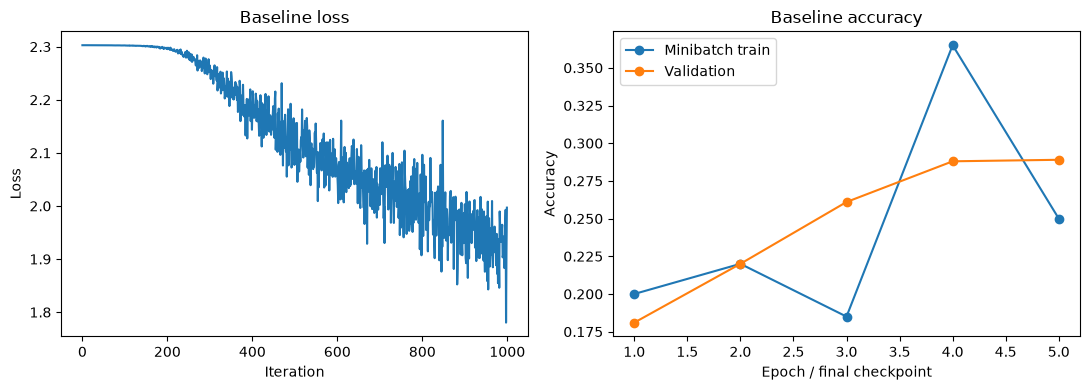

In [12]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
axes[0].plot(stats['loss_history'])
axes[0].set(xlabel='Iteration', ylabel='Loss', title='Baseline loss')
epochs = np.arange(1, len(stats['train_acc_history']) + 1)
axes[1].plot(epochs, stats['train_acc_history'], 'o-', label='Minibatch train')
axes[1].plot(epochs, stats['val_acc_history'], 'o-', label='Validation')
axes[1].set(xlabel='Epoch / final checkpoint', ylabel='Accuracy', title='Baseline accuracy')
axes[1].legend()
plt.tight_layout()
plt.show()

# Check full-training accuracy too, since minibatch accuracy is noisy.
print('Full training accuracy:', np.mean(subopt_net.predict(X_train) == y_train))
print('Validation accuracy:', np.mean(subopt_net.predict(X_val) == y_val))
print('Mean loss, first 100 iterations:', np.mean(stats['loss_history'][:100]))
print('Mean loss, last 100 iterations:', np.mean(stats['loss_history'][-100:]))
for name in ('W1', 'W2'):
    print(name, 'standard deviation:', np.std(subopt_net.params[name]))


## Answers:

(1) The full training accuracy is 29.3% and the validation accuracy is 28.9%, so the main problem is underfitting or slow optimization rather than a large difference between training and validation. The loss is still decreasing at the end of the run. The learning rate is small, and 1000 updates cover only about four epochs. Also, the initial weights have standard deviation $10^{-4}$, so the initial hidden activations and weight gradients are small.

(2) I would increase the learning rate and train for more iterations, since the loss is still decreasing. I would also try a larger initial weight scale and tune the regularization strength. I would compare these settings using validation accuracy while keeping the hidden layer at 50 units.

In the tuning experiment below, I trained longer and tried larger learning rates, a larger initial weight scale, and different regularization strengths. The best setting used a learning rate of $8\times10^{-4}$, regularization of $0.15$, and initial weight standard deviation of $0.01$. Training for 10000 updates with learning-rate decay of $0.97$ per epoch gave a best validation accuracy of 53.2%.


## Optimize the neural network

Use the following part of the Jupyter notebook to optimize your hyperparameters on the validation set.  Store your nets as best_net.

lr = 0.0008, reg = 0.05: best val = 0.520 at iteration 9800
lr = 0.0008, reg = 0.15: best val = 0.532 at iteration 9800
lr = 0.0012, reg = 0.05: best val = 0.512 at iteration 10000
lr = 0.0012, reg = 0.15: best val = 0.517 at iteration 7350
Best (learning rate, regularization): (0.0008, 0.15)
Best validation accuracy: 0.532
Best full training accuracy: 0.5969183673469388


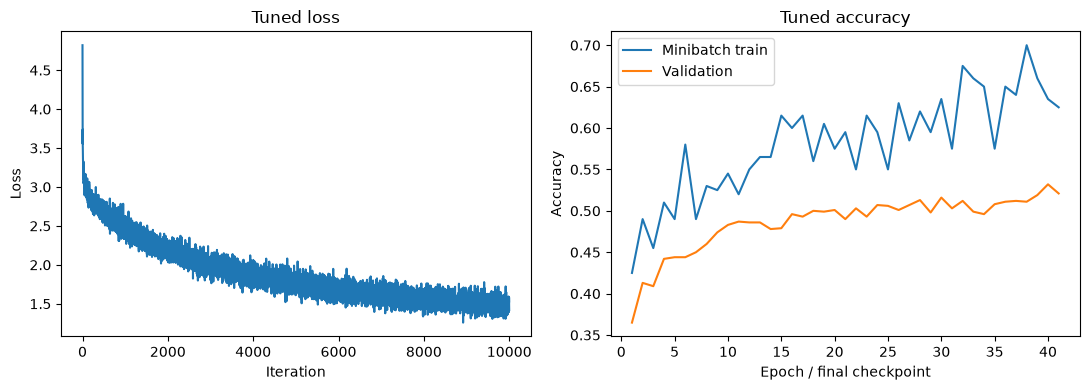

In [13]:
# Keep the same 3072 -> 50 -> 10 network and use minibatch SGD.
# Choose the learning rate and regularization using only the validation set.
configs = [
    (8e-4, 0.05),
    (8e-4, 0.15),
    (1.2e-3, 0.05),
    (1.2e-3, 0.15),
]
best_net = None
best_val_acc = -1
best_stats = None
results = []

for learning_rate, reg in configs:
    # Use the same initialization and minibatch sequence for each setting.
    np.random.seed(123)
    candidate = TwoLayerNet(input_size, 50, num_classes, std=1e-2)
    candidate.params = {name: value.astype(np.float32)
                        for name, value in candidate.params.items()}
    candidate_stats = candidate.train(
        X_train, y_train, X_val, y_val,
        learning_rate=learning_rate, learning_rate_decay=0.97,
        reg=reg, num_iters=10000, batch_size=200, verbose=False)

    # Restore the epoch with the highest validation accuracy for this run.
    candidate.params = {name: value.copy()
                        for name, value in candidate_stats['best_params'].items()}
    candidate_val_acc = np.mean(candidate.predict(X_val) == y_val)
    results.append((learning_rate, reg, candidate_val_acc))
    print('lr = %.4g, reg = %.3g: best val = %.3f at iteration %d' %
          (learning_rate, reg, candidate_val_acc, candidate_stats['best_iteration']))
    if candidate_val_acc > best_val_acc:
        best_val_acc = candidate_val_acc
        best_net = candidate
        best_stats = candidate_stats
        best_config = (learning_rate, reg)

print('Best (learning rate, regularization):', best_config)
print('Best validation accuracy:', best_val_acc)
print('Best full training accuracy:', np.mean(best_net.predict(X_train) == y_train))

fig, axes = plt.subplots(1, 2, figsize=(11, 4))
axes[0].plot(best_stats['loss_history'])
axes[0].set(xlabel='Iteration', ylabel='Loss', title='Tuned loss')
epochs = np.arange(1, len(best_stats['train_acc_history']) + 1)
axes[1].plot(epochs, best_stats['train_acc_history'], label='Minibatch train')
axes[1].plot(epochs, best_stats['val_acc_history'], label='Validation')
axes[1].set(xlabel='Epoch / final checkpoint', ylabel='Accuracy', title='Tuned accuracy')
axes[1].legend()
plt.tight_layout()
plt.show()


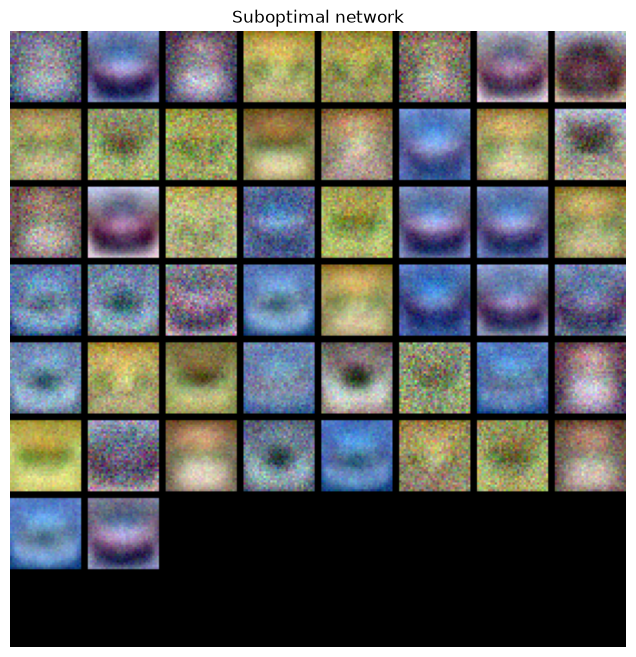

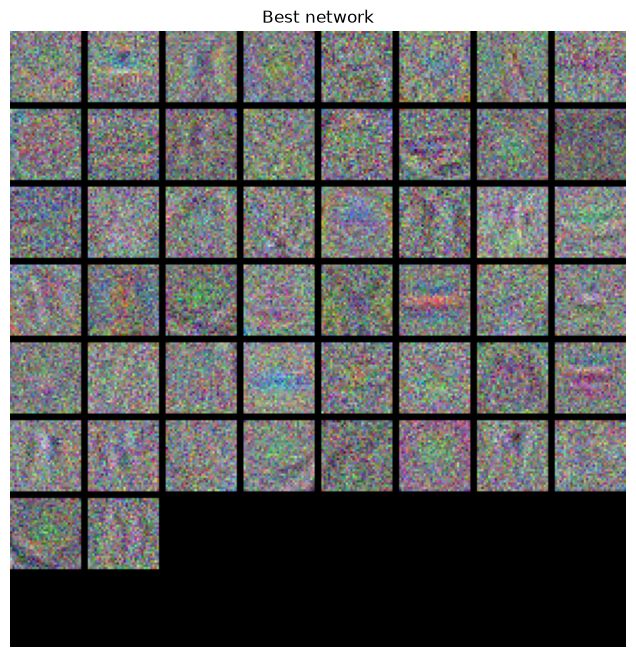

In [14]:
from math import sqrt, ceil
import numpy as np

def visualize_grid(Xs, ubound=255.0, padding=1):
  """
  Reshape a 4D tensor of image data to a grid for easy visualization.

  Inputs:
  - Xs: Data of shape (N, H, W, C)
  - ubound: Output grid will have values scaled to the range [0, ubound]
  - padding: The number of blank pixels between elements of the grid
  """
  (N, H, W, C) = Xs.shape
  grid_size = int(ceil(sqrt(N)))
  grid_height = H * grid_size + padding * (grid_size - 1)
  grid_width = W * grid_size + padding * (grid_size - 1)
  grid = np.zeros((grid_height, grid_width, C))
  next_idx = 0
  y0, y1 = 0, H
  for y in np.arange(grid_size):
    x0, x1 = 0, W
    for x in np.arange(grid_size):
      if next_idx < N:
        img = Xs[next_idx]
        low, high = np.min(img), np.max(img)
        grid[y0:y1, x0:x1] = ubound * (img - low) / max(high - low, 1e-8)
        # grid[y0:y1, x0:x1] = Xs[next_idx]
        next_idx += 1
      x0 += W + padding
      x1 += W + padding
    y0 += H + padding
    y1 += H + padding
  # grid_max = np.max(grid)
  # grid_min = np.min(grid)
  # grid = ubound * (grid - grid_min) / (grid_max - grid_min)
  return grid


def show_net_weights(net, title):
    W1 = net.params['W1'].reshape(50, 32, 32, 3)
    plt.figure(figsize=(8, 8))
    plt.imshow(visualize_grid(W1, padding=3).astype('uint8'))
    plt.title(title)
    plt.axis('off')
    plt.show()

show_net_weights(subopt_net, 'Suboptimal network')
show_net_weights(best_net, 'Best network')


## Question:

(1) What differences do you see in the weights between the suboptimal net and the best net you arrived at?

## Answer:

(1) The suboptimal network has several similar smooth color and light/dark blobs. The best network's filters look more varied but also noisier. I used a larger initial weight scale for the tuned network, so more random texture remains visible. Despite this, it has higher validation accuracy; smoother-looking individual filters do not necessarily give a better classifier. Each filter is scaled separately in the plot, so brightness alone does not compare the actual weight magnitudes.


## Evaluate on test set

In [15]:
test_acc = (best_net.predict(X_test) == y_test).mean()
print('Test accuracy: ', test_acc)

Test accuracy:  0.493


# Problem 5: Fully connected networks

**Neural Networks & Deep Learning - ECE C147A/C247A, UCLA Fall 2026**  
**Instructor:** Prof. Suhas Diggavi  
**TAs:** A. Kadiyala, B. Huang, M.Y. Turali, K. Pang, S.Y. Yetim  
**Released:** Monday, October 12, 2026  
**Due:** Friday, October 23, 2026, 11:59 PM Pacific Time  
**HW3 Problem 5:** 20 points

In the previous notebook, you implemented a simple two-layer neural network class.  However, this class is not modular.  If you wanted to change the number of layers, you would need to write a new loss and gradient function.  If you wanted to optimize the network with different optimizers, you'd need to write new training functions.  If you wanted to incorporate regularizations, you'd have to modify the loss and gradient function.  

Instead of having to modify functions each time, for the rest of the class, we'll work in a more modular framework where we define forward and backward layers that calculate losses and gradients respectively.  Since the forward and backward layers share intermediate values that are useful for calculating both the loss and the gradient, we'll also have these function return "caches" which store useful intermediate values.

The goal is that through this modular design, we can build different sized neural networks for various applications.

In this HW #3, we'll define the basic architecture, and in HW #4, we'll build on this framework to implement different optimizers and regularizations (like BatchNorm and Dropout).

CS231n has built a solid API for building these modular frameworks and training them, and we will use their very well implemented framework as opposed to "reinventing the wheel."  This includes using their Solver, various utility functions, and their layer structure.  This also includes nndl.fc_net, nndl.layers, and nndl.layer_utils.  As in prior assignments, we thank Serena Yeung & Justin Johnson for permission to use code written for the CS 231n class (cs231n.stanford.edu).  
For Colab, the required implementations and supplied helper code are embedded below. The supplied Solver class is unchanged. Run Problem 4's CIFAR-10 loading cell first. `ModularTwoLayerNet` is Problem 5's `TwoLayerNet`, renamed to distinguish it from Problem 4.


## Modular layers

This notebook will build modular layers in the following manner.  First, there will be a forward pass for a given layer with inputs (`x`) and return the output of that layer (`out`) as well as cached variables (`cache`) that will be used to calculate the gradient in the backward pass.

```python
def layer_forward(x, w):
  """ Receive inputs x and weights w """
  # Do some computations ...
  z = # ... some intermediate value
  # Do some more computations ...
  out = # the output
   
  cache = (x, w, z, out) # Values we need to compute gradients
   
  return out, cache
```

The backward pass will receive upstream derivatives and the `cache` object, and will return gradients with respect to the inputs and weights, like this:

```python
def layer_backward(dout, cache):
  """
  Receive derivative of loss with respect to outputs and cache,
  and compute derivative with respect to inputs.
  """
  # Unpack cache values
  x, w, z, out = cache
  
  # Use values in cache to compute derivatives
  dx = # Derivative of loss with respect to x
  dw = # Derivative of loss with respect to w
  
  return dx, dw
```

In [16]:
## Import and setups

import time
import numpy as np
import matplotlib.pyplot as plt

np.random.seed(0)

%matplotlib inline
plt.rcParams['figure.figsize'] = (10.0, 8.0) # set default size of plots
plt.rcParams['image.interpolation'] = 'nearest'
plt.rcParams['image.cmap'] = 'gray'

# for auto-reloading external modules
# see http://stackoverflow.com/questions/1907993/autoreload-of-modules-in-ipython
%load_ext autoreload
%autoreload 2

def rel_error(x, y):
  """ returns relative error """
  return np.max(np.abs(x - y) / (np.maximum(1e-8, np.abs(x) + np.abs(y))))

# Supplied numerical-gradient helpers, embedded for Colab.
def eval_numerical_gradient(f, x, verbose=True, h=0.00001):
  """ 
  a naive implementation of numerical gradient of f at x 
  - f should be a function that takes a single argument
  - x is the point (numpy array) to evaluate the gradient at
  """ 

  fx = f(x) # evaluate function value at original point
  grad = np.zeros_like(x)
  # iterate over all indexes in x
  it = np.nditer(x, flags=['multi_index'], op_flags=['readwrite'])
  while not it.finished:

    # evaluate function at x+h
    ix = it.multi_index
    oldval = x[ix]
    x[ix] = oldval + h # increment by h
    fxph = f(x) # evalute f(x + h)
    x[ix] = oldval - h
    fxmh = f(x) # evaluate f(x - h)
    x[ix] = oldval # restore

    # compute the partial derivative with centered formula
    grad[ix] = (fxph - fxmh) / (2 * h) # the slope
    if verbose:
      print(ix, grad[ix])
    it.iternext() # step to next dimension

  return grad

def eval_numerical_gradient_array(f, x, df, h=1e-5):
  """
  Evaluate a numeric gradient for a function that accepts a numpy
  array and returns a numpy array.
  """
  grad = np.zeros_like(x)
  it = np.nditer(x, flags=['multi_index'], op_flags=['readwrite'])
  while not it.finished:
    ix = it.multi_index
    
    oldval = x[ix]
    x[ix] = oldval + h
    pos = f(x).copy()
    x[ix] = oldval - h
    neg = f(x).copy()
    x[ix] = oldval
    
    grad[ix] = np.sum((pos - neg) * df) / (2 * h)
    it.iternext()
  return grad


In [17]:
# Reuse the mean-centered CIFAR-10 arrays loaded in Problem 4.
# This is the channel-first layout used by the supplied FC notebook.
data = {
    'X_train': X_train.reshape(-1, 32, 32, 3).transpose(0, 3, 1, 2),
    'y_train': y_train,
    'X_val': X_val.reshape(-1, 32, 32, 3).transpose(0, 3, 1, 2),
    'y_val': y_val,
    'X_test': X_test.reshape(-1, 32, 32, 3).transpose(0, 3, 1, 2),
    'y_test': y_test,
}
for key, value in data.items():
    print(key + ':', value.shape)


X_train: (49000, 3, 32, 32)
y_train: (49000,)
X_val: (1000, 3, 32, 32)
y_val: (1000,)
X_test: (1000, 3, 32, 32)
y_test: (1000,)


## Linear layers

In this section, we'll implement the forward and backward pass for the linear layers.

The linear layer forward pass is the function `affine_forward` in `nndl/layers.py` and the backward pass is `affine_backward`.

After you have implemented these, test your implementation by running the cell below.

### Affine layer forward pass

Implement `affine_forward` and then test your code by running the following cell.

In [18]:
def affine_forward(x, w, b):
    x_flat = x.reshape(x.shape[0], -1)
    out = x_flat @ w + b
    return out, (x, w, b)


def affine_backward(dout, cache):
    x, w, b = cache
    x_flat = x.reshape(x.shape[0], -1)
    dx = (dout @ w.T).reshape(x.shape)
    dw = x_flat.T @ dout
    db = np.sum(dout, axis=0)
    return dx, dw, db


def relu_forward(x):
    return np.maximum(0, x), x


def relu_backward(dout, cache):
    return dout * (cache > 0)


def affine_relu_forward(x, w, b):
  """
  Convenience layer that performs an affine transform followed by a ReLU

  Inputs:
  - x: Input to the affine layer
  - w, b: Weights for the affine layer

  Returns a tuple of:
  - out: Output from the ReLU
  - cache: Object to give to the backward pass
  """
  a, fc_cache = affine_forward(x, w, b)
  out, relu_cache = relu_forward(a)
  cache = (fc_cache, relu_cache)
  return out, cache

def affine_relu_backward(dout, cache):
  """
  Backward pass for the affine-relu convenience layer
  """
  fc_cache, relu_cache = cache
  da = relu_backward(dout, relu_cache)
  dx, dw, db = affine_backward(da, fc_cache)
  return dx, dw, db

def svm_loss(x, y):
  """
  Computes the loss and gradient using for multiclass SVM classification.

  Inputs:
  - x: Input data, of shape (N, C) where x[i, j] is the score for the jth class
    for the ith input.
  - y: Vector of labels, of shape (N,) where y[i] is the label for x[i] and
    0 <= y[i] < C

  Returns a tuple of:
  - loss: Scalar giving the loss
  - dx: Gradient of the loss with respect to x
  """
  N = x.shape[0]
  correct_class_scores = x[np.arange(N), y]
  margins = np.maximum(0, x - correct_class_scores[:, np.newaxis] + 1.0)
  margins[np.arange(N), y] = 0
  loss = np.sum(margins) / N
  num_pos = np.sum(margins > 0, axis=1)
  dx = np.zeros_like(x)
  dx[margins > 0] = 1
  dx[np.arange(N), y] -= num_pos
  dx /= N
  return loss, dx

def softmax_loss(x, y):
  """
  Computes the loss and gradient for softmax classification.

  Inputs:
  - x: Input data, of shape (N, C) where x[i, j] is the score for the jth class
    for the ith input.
  - y: Vector of labels, of shape (N,) where y[i] is the label for x[i] and
    0 <= y[i] < C

  Returns a tuple of:
  - loss: Scalar giving the loss
  - dx: Gradient of the loss with respect to x
  """

  probs = np.exp(x - np.max(x, axis=1, keepdims=True))
  probs /= np.sum(probs, axis=1, keepdims=True)
  N = x.shape[0]
  loss = -np.sum(np.log(probs[np.arange(N), y])) / N
  dx = probs.copy()
  dx[np.arange(N), y] -= 1
  dx /= N
  return loss, dx


In [19]:
# Test the affine_forward function

num_inputs = 2
input_shape = (4, 5, 6)
output_dim = 3

input_size = num_inputs * np.prod(input_shape)
weight_size = output_dim * np.prod(input_shape)

x = np.linspace(-0.1, 0.5, num=input_size).reshape(num_inputs, *input_shape)
w = np.linspace(-0.2, 0.3, num=weight_size).reshape(np.prod(input_shape), output_dim)
b = np.linspace(-0.3, 0.1, num=output_dim)

out, _ = affine_forward(x, w, b)
correct_out = np.array([[ 1.49834967,  1.70660132,  1.91485297],
                        [ 3.25553199,  3.5141327,   3.77273342]])

# Compare your output with ours. The error should be around 1e-9.
print('Testing affine_forward function:')
print('difference: {}'.format(rel_error(out, correct_out)))

Testing affine_forward function:
difference: 9.769849468192957e-10


### Affine layer backward pass

Implement `affine_backward` and then test your code by running the following cell.

In [20]:
# Test the affine_backward function

x = np.random.randn(10, 2, 3)
w = np.random.randn(6, 5)
b = np.random.randn(5)
dout = np.random.randn(10, 5)

dx_num = eval_numerical_gradient_array(lambda x: affine_forward(x, w, b)[0], x, dout)
dw_num = eval_numerical_gradient_array(lambda w: affine_forward(x, w, b)[0], w, dout)
db_num = eval_numerical_gradient_array(lambda b: affine_forward(x, w, b)[0], b, dout)

_, cache = affine_forward(x, w, b)
dx, dw, db = affine_backward(dout, cache)

# The error should be around 1e-10
print('Testing affine_backward function:')
print('dx error: {}'.format(rel_error(dx_num, dx)))
print('dw error: {}'.format(rel_error(dw_num, dw)))
print('db error: {}'.format(rel_error(db_num, db)))

Testing affine_backward function:
dx error: 3.2142220994073864e-10
dw error: 6.700872904884422e-10
db error: 1.7414420254267542e-10


## Activation layers

In this section you'll implement the ReLU activation.

### ReLU forward pass

Implement the `relu_forward` function in `nndl/layers.py` and then test your code by running the following cell.

In [21]:
# Test the relu_forward function

x = np.linspace(-0.5, 0.5, num=12).reshape(3, 4)

out, _ = relu_forward(x)
correct_out = np.array([[ 0.,          0.,          0.,          0.,        ],
                        [ 0.,          0.,          0.04545455,  0.13636364,],
                        [ 0.22727273,  0.31818182,  0.40909091,  0.5,       ]])

# Compare your output with ours. The error should be around 1e-8
print('Testing relu_forward function:')
print('difference: {}'.format(rel_error(out, correct_out)))

Testing relu_forward function:
difference: 4.999999798022158e-08


### ReLU backward pass
Implement the `relu_backward` function in `nndl/layers.py` and then test your code by running the following cell.

In [22]:
x = np.random.randn(10, 10)
dout = np.random.randn(*x.shape)

dx_num = eval_numerical_gradient_array(lambda x: relu_forward(x)[0], x, dout)

_, cache = relu_forward(x)
dx = relu_backward(dout, cache)

# The error should be around 1e-12
print('Testing relu_backward function:')
print('dx error: {}'.format(rel_error(dx_num, dx)))

Testing relu_backward function:
dx error: 3.2756149247600615e-12


## Combining the affine and ReLU layers

Often times, an affine layer will be followed by a ReLU layer. So let's make one that puts them together.  Layers that are combined are stored in `nndl/layer_utils.py`.  

### Affine-ReLU layers
We've implemented `affine_relu_forward()` and `affine_relu_backward` in ``nndl/layer_utils.py``.  Take a look at them to make sure you understand what's going on.  Then run the following cell to ensure its implemented correctly.

In [23]:
x = np.random.randn(2, 3, 4)
w = np.random.randn(12, 10)
b = np.random.randn(10)
dout = np.random.randn(2, 10)

out, cache = affine_relu_forward(x, w, b)
dx, dw, db = affine_relu_backward(dout, cache)

dx_num = eval_numerical_gradient_array(lambda x: affine_relu_forward(x, w, b)[0], x, dout)
dw_num = eval_numerical_gradient_array(lambda w: affine_relu_forward(x, w, b)[0], w, dout)
db_num = eval_numerical_gradient_array(lambda b: affine_relu_forward(x, w, b)[0], b, dout)

print('Testing affine_relu_forward and affine_relu_backward:')
print('dx error: {}'.format(rel_error(dx_num, dx)))
print('dw error: {}'.format(rel_error(dw_num, dw)))
print('db error: {}'.format(rel_error(db_num, db)))

Testing affine_relu_forward and affine_relu_backward:
dx error: 4.889679157419906e-10
dw error: 2.4665892046230285e-09
db error: 4.479232846812546e-12


## Softmax and SVM losses

You've already implemented these, so we have written these in `layers.py`.  The following code will ensure they are working correctly.

In [24]:
num_classes, num_inputs = 10, 50
x = 0.001 * np.random.randn(num_inputs, num_classes)
y = np.random.randint(num_classes, size=num_inputs)

dx_num = eval_numerical_gradient(lambda x: svm_loss(x, y)[0], x, verbose=False)
loss, dx = svm_loss(x, y)

# Test svm_loss function. Loss should be around 9 and dx error should be 1e-9
print('Testing svm_loss:')
print('loss: {}'.format(loss))
print('dx error: {}'.format(rel_error(dx_num, dx)))

dx_num = eval_numerical_gradient(lambda x: softmax_loss(x, y)[0], x, verbose=False)
loss, dx = softmax_loss(x, y)

# Test softmax_loss function. Loss should be 2.3 and dx error should be 1e-8
print('\nTesting softmax_loss:')
print('loss: {}'.format(loss))
print('dx error: {}'.format(rel_error(dx_num, dx)))

Testing svm_loss:
loss: 8.998046848988633
dx error: 8.182894472887002e-10

Testing softmax_loss:
loss: 2.302390208729082
dx error: 1.0401408974087217e-08


## Implementation of a two-layer NN

In `nndl/fc_net.py`, implement the class `TwoLayerNet` which uses the layers you made here.  When you have finished, the following cell will test your implementation.

In [25]:
class ModularTwoLayerNet:
    # Same API as Problem 5's TwoLayerNet; a separate name keeps Problem 4 intact.
    def __init__(self, input_dim=3*32*32, hidden_dims=100, num_classes=10,
                 dropout=0, weight_scale=1e-3, reg=0.0):
        if dropout:
            raise NotImplementedError('Dropout is covered in HW4.')
        self.reg = reg
        self.params = {
            'W1': weight_scale * np.random.randn(input_dim, hidden_dims),
            'b1': np.zeros(hidden_dims),
            'W2': weight_scale * np.random.randn(hidden_dims, num_classes),
            'b2': np.zeros(num_classes),
        }

    def loss(self, X, y=None):
        h, hidden_cache = affine_relu_forward(X, self.params['W1'], self.params['b1'])
        scores, output_cache = affine_forward(h, self.params['W2'], self.params['b2'])
        if y is None:
            return scores

        loss, dscores = softmax_loss(scores, y)
        loss += 0.5 * self.reg * (np.sum(self.params['W1']**2)
                                 + np.sum(self.params['W2']**2))
        dh, dW2, db2 = affine_backward(dscores, output_cache)
        dx, dW1, db1 = affine_relu_backward(dh, hidden_cache)
        grads = {
            'W1': dW1 + self.reg * self.params['W1'], 'b1': db1,
            'W2': dW2 + self.reg * self.params['W2'], 'b2': db2,
        }
        return loss, grads



np.random.seed(231)


In [26]:
N, D, H, C = 3, 5, 50, 7
X = np.random.randn(N, D)
y = np.random.randint(C, size=N)

std = 1e-2
model = ModularTwoLayerNet(input_dim=D, hidden_dims=H, num_classes=C, weight_scale=std)

print('Testing initialization ... ')
W1_std = abs(model.params['W1'].std() - std)
b1 = model.params['b1']
W2_std = abs(model.params['W2'].std() - std)
b2 = model.params['b2']
assert W1_std < std / 10, 'First layer weights do not seem right'
assert np.all(b1 == 0), 'First layer biases do not seem right'
assert W2_std < std / 10, 'Second layer weights do not seem right'
assert np.all(b2 == 0), 'Second layer biases do not seem right'

print('Testing test-time forward pass ... ')
model.params['W1'] = np.linspace(-0.7, 0.3, num=D*H).reshape(D, H)
model.params['b1'] = np.linspace(-0.1, 0.9, num=H)
model.params['W2'] = np.linspace(-0.3, 0.4, num=H*C).reshape(H, C)
model.params['b2'] = np.linspace(-0.9, 0.1, num=C)
X = np.linspace(-5.5, 4.5, num=N*D).reshape(D, N).T
scores = model.loss(X)
correct_scores = np.asarray(
  [[11.53165108,  12.2917344,   13.05181771,  13.81190102,  14.57198434, 15.33206765,  16.09215096],
   [12.05769098,  12.74614105,  13.43459113,  14.1230412,   14.81149128, 15.49994135,  16.18839143],
   [12.58373087,  13.20054771,  13.81736455,  14.43418138,  15.05099822, 15.66781506,  16.2846319 ]])
scores_diff = np.abs(scores - correct_scores).sum()
assert scores_diff < 1e-6, 'Problem with test-time forward pass'

print('Testing training loss (no regularization)')
y = np.asarray([0, 5, 1])
loss, grads = model.loss(X, y)
correct_loss = 3.4702243556
assert abs(loss - correct_loss) < 1e-10, 'Problem with training-time loss'

model.reg = 1.0
loss, grads = model.loss(X, y)
correct_loss = 26.5948426952
assert abs(loss - correct_loss) < 1e-10, 'Problem with regularization loss'

for reg in [0.0, 0.7]:
  print('Running numeric gradient check with reg = {}'.format(reg))
  model.reg = reg
  loss, grads = model.loss(X, y)

  for name in sorted(grads):
    f = lambda _: model.loss(X, y)[0]
    grad_num = eval_numerical_gradient(f, model.params[name], verbose=False)
    print('{} relative error: {}'.format(name, rel_error(grad_num, grads[name])))

Testing initialization ... 
Testing test-time forward pass ... 
Testing training loss (no regularization)
Running numeric gradient check with reg = 0.0
W1 relative error: 1.2236150500701354e-08
W2 relative error: 3.4323088416617995e-10
b1 relative error: 9.828315773285823e-09
b2 relative error: 2.530784768782457e-10
Running numeric gradient check with reg = 0.7
W1 relative error: 2.527915175868136e-07
W2 relative error: 1.3678354331876478e-07
b1 relative error: 1.5646801678531443e-08
b2 relative error: 9.089621155678095e-10


## Solver 

We will now use the cs231n Solver class to train these networks.  Familiarize yourself with the API in `cs231n/solver.py`.  After you have done so, declare an instance of a TwoLayerNet with 200 units and then train it with the Solver.  Choose parameters so that your validation accuracy is at least 40%.

In [27]:
from __future__ import print_function, division
from builtins import range
from builtins import object
import os
import pickle as pickle

import numpy as np

# Supplied SGD is embedded here instead of imported from nndl.optim.
from types import SimpleNamespace

def sgd(w, dw, config=None):
  """
  Performs vanilla stochastic gradient descent.

  config format:
  - learning_rate: Scalar learning rate.
  """
  if config is None: config = {}
  config.setdefault('learning_rate', 1e-2)

  w -= config['learning_rate'] * dw
  return w, config

optim = SimpleNamespace(sgd=sgd)


class Solver(object):
    """
    A Solver encapsulates all the logic necessary for training classification
    models. The Solver performs stochastic gradient descent using different
    update rules defined in optim.py.

    The solver accepts both training and validataion data and labels so it can
    periodically check classification accuracy on both training and validation
    data to watch out for overfitting.

    To train a model, you will first construct a Solver instance, passing the
    model, dataset, and various optoins (learning rate, batch size, etc) to the
    constructor. You will then call the train() method to run the optimization
    procedure and train the model.

    After the train() method returns, model.params will contain the parameters
    that performed best on the validation set over the course of training.
    In addition, the instance variable solver.loss_history will contain a list
    of all losses encountered during training and the instance variables
    solver.train_acc_history and solver.val_acc_history will be lists of the
    accuracies of the model on the training and validation set at each epoch.

    Example usage might look something like this:

    data = {
      'X_train': # training data
      'y_train': # training labels
      'X_val': # validation data
      'y_val': # validation labels
    }
    model = MyAwesomeModel(hidden_size=100, reg=10)
    solver = Solver(model, data,
                    update_rule='sgd',
                    optim_config={
                      'learning_rate': 1e-3,
                    },
                    lr_decay=0.95,
                    num_epochs=10, batch_size=100,
                    print_every=100)
    solver.train()


    A Solver works on a model object that must conform to the following API:

    - model.params must be a dictionary mapping string parameter names to numpy
      arrays containing parameter values.

    - model.loss(X, y) must be a function that computes training-time loss and
      gradients, and test-time classification scores, with the following inputs
      and outputs:

      Inputs:
      - X: Array giving a minibatch of input data of shape (N, d_1, ..., d_k)
      - y: Array of labels, of shape (N,) giving labels for X where y[i] is the
        label for X[i].

      Returns:
      If y is None, run a test-time forward pass and return:
      - scores: Array of shape (N, C) giving classification scores for X where
        scores[i, c] gives the score of class c for X[i].

      If y is not None, run a training time forward and backward pass and
      return a tuple of:
      - loss: Scalar giving the loss
      - grads: Dictionary with the same keys as self.params mapping parameter
        names to gradients of the loss with respect to those parameters.
    """

    def __init__(self, model, data, **kwargs):
        """
        Construct a new Solver instance.

        Required arguments:
        - model: A model object conforming to the API described above
        - data: A dictionary of training and validation data containing:
          'X_train': Array, shape (N_train, d_1, ..., d_k) of training images
          'X_val': Array, shape (N_val, d_1, ..., d_k) of validation images
          'y_train': Array, shape (N_train,) of labels for training images
          'y_val': Array, shape (N_val,) of labels for validation images

        Optional arguments:
        - update_rule: A string giving the name of an update rule in optim.py.
          Default is 'sgd'.
        - optim_config: A dictionary containing hyperparameters that will be
          passed to the chosen update rule. Each update rule requires different
          hyperparameters (see optim.py) but all update rules require a
          'learning_rate' parameter so that should always be present.
        - lr_decay: A scalar for learning rate decay; after each epoch the
          learning rate is multiplied by this value.
        - batch_size: Size of minibatches used to compute loss and gradient
          during training.
        - num_epochs: The number of epochs to run for during training.
        - print_every: Integer; training losses will be printed every
          print_every iterations.
        - verbose: Boolean; if set to false then no output will be printed
          during training.
        - num_train_samples: Number of training samples used to check training
          accuracy; default is 1000; set to None to use entire training set.
        - num_val_samples: Number of validation samples to use to check val
          accuracy; default is None, which uses the entire validation set.
        - checkpoint_name: If not None, then save model checkpoints here every
          epoch.
        """
        self.model = model
        self.X_train = data['X_train']
        self.y_train = data['y_train']
        self.X_val = data['X_val']
        self.y_val = data['y_val']

        # Unpack keyword arguments
        self.update_rule = kwargs.pop('update_rule', 'sgd')
        self.optim_config = kwargs.pop('optim_config', {})
        self.lr_decay = kwargs.pop('lr_decay', 1.0)
        self.batch_size = kwargs.pop('batch_size', 100)
        self.num_epochs = kwargs.pop('num_epochs', 10)
        self.num_train_samples = kwargs.pop('num_train_samples', 1000)
        self.num_val_samples = kwargs.pop('num_val_samples', None)

        self.checkpoint_name = kwargs.pop('checkpoint_name', None)
        self.print_every = kwargs.pop('print_every', 10)
        self.verbose = kwargs.pop('verbose', True)

        # Throw an error if there are extra keyword arguments
        if len(kwargs) > 0:
            extra = ', '.join('"%s"' % k for k in list(kwargs.keys()))
            raise ValueError('Unrecognized arguments %s' % extra)

        # Make sure the update rule exists, then replace the string
        # name with the actual function
        if not hasattr(optim, self.update_rule):
            raise ValueError('Invalid update_rule "%s"' % self.update_rule)
        self.update_rule = getattr(optim, self.update_rule)

        self._reset()


    def _reset(self):
        """
        Set up some book-keeping variables for optimization. Don't call this
        manually.
        """
        # Set up some variables for book-keeping
        self.epoch = 0
        self.best_val_acc = 0
        self.best_params = {}
        self.loss_history = []
        self.train_acc_history = []
        self.val_acc_history = []

        # Make a deep copy of the optim_config for each parameter
        self.optim_configs = {}
        for p in self.model.params:
            d = {k: v for k, v in self.optim_config.items()}
            self.optim_configs[p] = d


    def _step(self):
        """
        Make a single gradient update. This is called by train() and should not
        be called manually.
        """
        # Make a minibatch of training data
        num_train = self.X_train.shape[0]
        batch_mask = np.random.choice(num_train, self.batch_size)
        X_batch = self.X_train[batch_mask]
        y_batch = self.y_train[batch_mask]

        # Compute loss and gradient
        loss, grads = self.model.loss(X_batch, y_batch)
        self.loss_history.append(loss)

        # Perform a parameter update
        for p, w in self.model.params.items():
            dw = grads[p]
            config = self.optim_configs[p]
            next_w, next_config = self.update_rule(w, dw, config)
            self.model.params[p] = next_w
            self.optim_configs[p] = next_config


    def _save_checkpoint(self):
        if self.checkpoint_name is None: return
        checkpoint = {
          'model': self.model,
          'update_rule': self.update_rule,
          'lr_decay': self.lr_decay,
          'optim_config': self.optim_config,
          'batch_size': self.batch_size,
          'num_train_samples': self.num_train_samples,
          'num_val_samples': self.num_val_samples,
          'epoch': self.epoch,
          'loss_history': self.loss_history,
          'train_acc_history': self.train_acc_history,
          'val_acc_history': self.val_acc_history,
        }
        filename = '%s_epoch_%d.pkl' % (self.checkpoint_name, self.epoch)
        if self.verbose:
            print('Saving checkpoint to "%s"' % filename)
        with open(filename, 'wb') as f:
            pickle.dump(checkpoint, f)


    def check_accuracy(self, X, y, num_samples=None, batch_size=100):
        """
        Check accuracy of the model on the provided data.

        Inputs:
        - X: Array of data, of shape (N, d_1, ..., d_k)
        - y: Array of labels, of shape (N,)
        - num_samples: If not None, subsample the data and only test the model
          on num_samples datapoints.
        - batch_size: Split X and y into batches of this size to avoid using
          too much memory.

        Returns:
        - acc: Scalar giving the fraction of instances that were correctly
          classified by the model.
        """

        # Maybe subsample the data
        N = X.shape[0]
        if num_samples is not None and N > num_samples:
            mask = np.random.choice(N, num_samples)
            N = num_samples
            X = X[mask]
            y = y[mask]

        # Compute predictions in batches
        num_batches = N // batch_size
        if N % batch_size != 0:
            num_batches += 1
        y_pred = []
        for i in range(num_batches):
            start = i * batch_size
            end = (i + 1) * batch_size
            scores = self.model.loss(X[start:end])
            y_pred.append(np.argmax(scores, axis=1))
        y_pred = np.hstack(y_pred)
        acc = np.mean(y_pred == y)

        return acc


    def train(self):
        """
        Run optimization to train the model.
        """
        num_train = self.X_train.shape[0]
        iterations_per_epoch = max(num_train // self.batch_size, 1)
        num_iterations = self.num_epochs * iterations_per_epoch

        for t in range(num_iterations):
            self._step()

            # Maybe print training loss
            if self.verbose and t % self.print_every == 0:
                print('(Iteration %d / %d) loss: %f' % (
                       t + 1, num_iterations, self.loss_history[-1]))

            # At the end of every epoch, increment the epoch counter and decay
            # the learning rate.
            epoch_end = (t + 1) % iterations_per_epoch == 0
            if epoch_end:
                self.epoch += 1
                for k in self.optim_configs:
                    self.optim_configs[k]['learning_rate'] *= self.lr_decay

            # Check train and val accuracy on the first iteration, the last
            # iteration, and at the end of each epoch.
            first_it = (t == 0)
            last_it = (t == num_iterations - 1)
            if first_it or last_it or epoch_end:
                train_acc = self.check_accuracy(self.X_train, self.y_train,
                    num_samples=self.num_train_samples)
                val_acc = self.check_accuracy(self.X_val, self.y_val,
                    num_samples=self.num_val_samples)
                self.train_acc_history.append(train_acc)
                self.val_acc_history.append(val_acc)
                self._save_checkpoint()

                if self.verbose:
                    print('(Epoch %d / %d) train acc: %f; val_acc: %f' % (
                           self.epoch, self.num_epochs, train_acc, val_acc))

                # Keep track of the best model
                if val_acc > self.best_val_acc:
                    self.best_val_acc = val_acc
                    self.best_params = {}
                    for k, v in self.model.params.items():
                        self.best_params[k] = v.copy()

        # At the end of training swap the best params into the model
        self.model.params = self.best_params


In [28]:
model = ModularTwoLayerNet()
solver = None

# ================================================================ #
# YOUR CODE HERE:
#   Declare an instance of a TwoLayerNet and then train 
#   it with the Solver. Choose hyperparameters so that your validation 
#   accuracy is at least 40%.  We won't have you optimize this further
#   since you did it in the previous notebook.
#
# ================================================================ #

np.random.seed(42)
model = ModularTwoLayerNet(hidden_dims=200, weight_scale=1e-2, reg=0.1)
solver = Solver(model, data, update_rule='sgd',
                optim_config={'learning_rate': 8e-4}, lr_decay=0.95,
                num_epochs=10, batch_size=200, print_every=500)
solver.train()
print('Best validation accuracy:', solver.best_val_acc)

# ================================================================ #
# END YOUR CODE HERE
# ================================================================ #

(Iteration 1 / 2450) loss: 9.046102
(Epoch 0 / 10) train acc: 0.134000; val_acc: 0.166000
(Epoch 1 / 10) train acc: 0.366000; val_acc: 0.374000
(Epoch 2 / 10) train acc: 0.418000; val_acc: 0.415000
(Iteration 501 / 2450) loss: 4.435167
(Epoch 3 / 10) train acc: 0.456000; val_acc: 0.431000
(Epoch 4 / 10) train acc: 0.458000; val_acc: 0.444000
(Iteration 1001 / 2450) loss: 4.196462
(Epoch 5 / 10) train acc: 0.508000; val_acc: 0.485000
(Epoch 6 / 10) train acc: 0.522000; val_acc: 0.488000
(Iteration 1501 / 2450) loss: 3.800432
(Epoch 7 / 10) train acc: 0.512000; val_acc: 0.478000
(Epoch 8 / 10) train acc: 0.520000; val_acc: 0.494000
(Iteration 2001 / 2450) loss: 3.677987
(Epoch 9 / 10) train acc: 0.544000; val_acc: 0.514000
(Epoch 10 / 10) train acc: 0.562000; val_acc: 0.502000
Best validation accuracy: 0.514


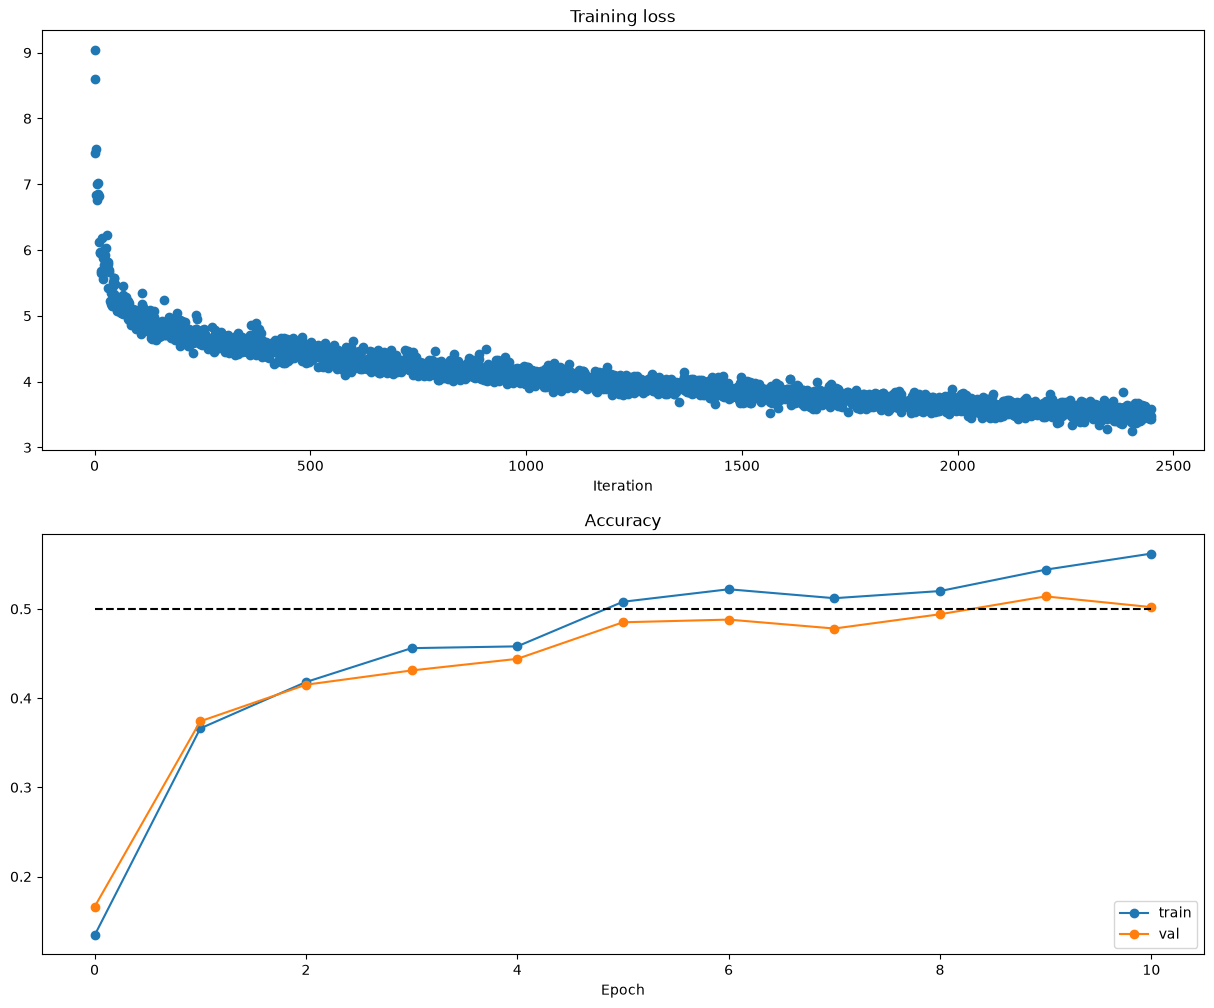

In [29]:
# Run this cell to visualize training loss and train / val accuracy

plt.subplot(2, 1, 1)
plt.title('Training loss')
plt.plot(solver.loss_history, 'o')
plt.xlabel('Iteration')

plt.subplot(2, 1, 2)
plt.title('Accuracy')
plt.plot(solver.train_acc_history, '-o', label='train')
plt.plot(solver.val_acc_history, '-o', label='val')
plt.plot([0.5] * len(solver.val_acc_history), 'k--')
plt.xlabel('Epoch')
plt.legend(loc='lower right')
plt.gcf().set_size_inches(15, 12)
plt.show()

The 200-unit two-layer network achieves **51.4% validation accuracy**, above the required 40%, using weight scale $0.01$, learning rate $8\times10^{-4}$, regularization $0.1$, and 10 epochs of SGD with learning-rate decay $0.95$.


## Multilayer Neural Network

Now, we implement a multi-layer neural network.

Read through the `FullyConnectedNet` class in the file `nndl/fc_net.py`.

Implement the initialization, the forward pass, and the backward pass.  There will be lines for batchnorm and dropout layers and caches; ignore these all for now.  That'll be in assignment #4.

In [30]:
class FullyConnectedNet:
    def __init__(self, hidden_dims, input_dim=3*32*32, num_classes=10,
                 dropout=0, use_batchnorm=False, reg=0.0,
                 weight_scale=1e-2, dtype=np.float32, seed=None):
        if dropout or use_batchnorm:
            raise NotImplementedError('Dropout and batch normalization are covered in HW4.')
        self.reg = reg
        self.dtype = dtype
        self.num_layers = len(hidden_dims) + 1
        self.params = {}
        dims = [input_dim] + list(hidden_dims) + [num_classes]
        for i in range(1, self.num_layers + 1):
            self.params['W%d' % i] = (weight_scale * np.random.randn(dims[i-1], dims[i])).astype(dtype)
            self.params['b%d' % i] = np.zeros(dims[i], dtype=dtype)

    def loss(self, X, y=None):
        out = X.astype(self.dtype, copy=False)
        caches = {}
        for i in range(1, self.num_layers):
            out, caches[i] = affine_relu_forward(out, self.params['W%d' % i],
                                                 self.params['b%d' % i])
        L = self.num_layers
        scores, caches[L] = affine_forward(out, self.params['W%d' % L], self.params['b%d' % L])
        if y is None:
            return scores

        loss, dout = softmax_loss(scores, y)
        grads = {}
        for i in range(L, 0, -1):
            W = self.params['W%d' % i]
            loss += 0.5 * self.reg * np.sum(W**2)
            if i == L:
                dout, dW, db = affine_backward(dout, caches[i])
            else:
                dout, dW, db = affine_relu_backward(dout, caches[i])
            grads['W%d' % i] = dW + self.reg * W
            grads['b%d' % i] = db
        return loss, grads

np.random.seed(231)


In [31]:
N, D, H1, H2, C = 2, 15, 20, 30, 10
X = np.random.randn(N, D)
y = np.random.randint(C, size=(N,))

for reg in [0, 3.14]:
  print('Running check with reg = {}'.format(reg))
  model = FullyConnectedNet([H1, H2], input_dim=D, num_classes=C,
                            reg=reg, weight_scale=5e-2, dtype=np.float64)

  loss, grads = model.loss(X, y)
  print('Initial loss: {}'.format(loss))

  for name in sorted(grads):
    f = lambda _: model.loss(X, y)[0]
    grad_num = eval_numerical_gradient(f, model.params[name], verbose=False, h=1e-5)
    print('{} relative error: {}'.format(name, rel_error(grad_num, grads[name])))

Running check with reg = 0
Initial loss: 2.300479089768492
W1 relative error: 1.0252674374835853e-07
W2 relative error: 2.2120479343503063e-05
W3 relative error: 4.5623278699709044e-07
b1 relative error: 4.660094372886962e-09
b2 relative error: 2.085654276112763e-09
b3 relative error: 1.689724888469736e-10
Running check with reg = 3.14
Initial loss: 7.052114776533016
W1 relative error: 8.180757135969596e-09
W2 relative error: 3.522821562176466e-08
W3 relative error: 1.1668674834289989e-08
b1 relative error: 1.4752427323253937e-08
b2 relative error: 1.4615869332918208e-09
b3 relative error: 1.3200479211447775e-10


(Iteration 1 / 40) loss: 2.349382
(Epoch 0 / 20) train acc: 0.280000; val_acc: 0.141000
(Epoch 1 / 20) train acc: 0.480000; val_acc: 0.157000
(Epoch 2 / 20) train acc: 0.520000; val_acc: 0.128000
(Epoch 3 / 20) train acc: 0.500000; val_acc: 0.166000
(Epoch 4 / 20) train acc: 0.580000; val_acc: 0.132000
(Epoch 5 / 20) train acc: 0.680000; val_acc: 0.181000
(Iteration 11 / 40) loss: 0.881306
(Epoch 6 / 20) train acc: 0.720000; val_acc: 0.151000
(Epoch 7 / 20) train acc: 0.720000; val_acc: 0.187000
(Epoch 8 / 20) train acc: 0.860000; val_acc: 0.171000
(Epoch 9 / 20) train acc: 0.960000; val_acc: 0.188000
(Epoch 10 / 20) train acc: 0.940000; val_acc: 0.166000
(Iteration 21 / 40) loss: 0.475039
(Epoch 11 / 20) train acc: 0.920000; val_acc: 0.169000
(Epoch 12 / 20) train acc: 0.980000; val_acc: 0.178000
(Epoch 13 / 20) train acc: 0.940000; val_acc: 0.177000
(Epoch 14 / 20) train acc: 0.960000; val_acc: 0.179000
(Epoch 15 / 20) train acc: 1.000000; val_acc: 0.189000
(Iteration 31 / 40) loss: 

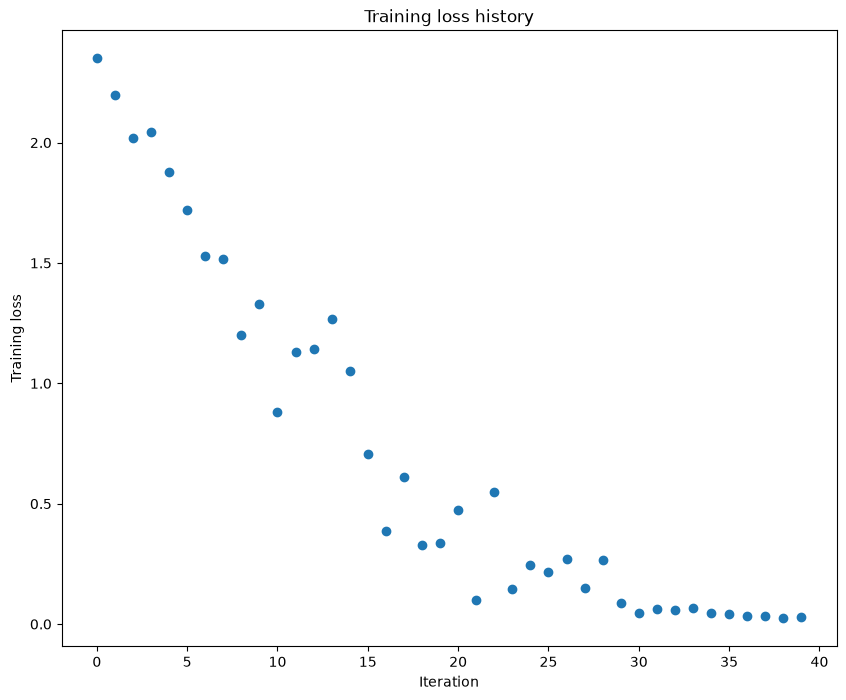

In [32]:
# Use the three layer neural network to overfit a small dataset.

num_train = 50
small_data = {
  'X_train': data['X_train'][:num_train],
  'y_train': data['y_train'][:num_train],
  'X_val': data['X_val'],
  'y_val': data['y_val'],
}


#### !!!!!!
# Play around with the weight_scale and learning_rate so that you can overfit a small dataset.
# Your training accuracy should be 1.0 to receive full credit on this part.
weight_scale = 1e-2
learning_rate = 1e-2

np.random.seed(2)
model = FullyConnectedNet([100, 100],
              weight_scale=weight_scale, dtype=np.float64)
solver = Solver(model, small_data,
                print_every=10, num_epochs=20, batch_size=25,
                update_rule='sgd',
                optim_config={
                  'learning_rate': learning_rate,
                }
         )
solver.train()
print('Training accuracy on all 50 images:',
      solver.check_accuracy(small_data['X_train'], small_data['y_train']))

plt.plot(solver.loss_history, 'o')
plt.title('Training loss history')
plt.xlabel('Iteration')
plt.ylabel('Training loss')
plt.show()

With weight scale $0.01$ and learning rate $0.01$, the three-layer network reaches 100% training accuracy on the 50 examples. The supplied Solver retains its usual behavior of restoring the best validation checkpoint; its restored model also achieves 100% training accuracy in this run.
